## Part B

### Prepare


In [1]:
#import lib
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

In [2]:
#load the dataset
iris = load_iris(as_frame=True)
data = iris.data

### Implement

In [3]:
#standardize 
scaler = StandardScaler()
X = scaler.fit_transform(data)

print("Data shape:", X.shape)
print("Features:", iris.feature_names)

Data shape: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [4]:
S = np.cov(X, rowvar=False)

print("Covariance matrix S:")
print(S)

Covariance matrix S:
[[ 1.00671141 -0.11835884  0.87760447  0.82343066]
 [-0.11835884  1.00671141 -0.43131554 -0.36858315]
 [ 0.87760447 -0.43131554  1.00671141  0.96932762]
 [ 0.82343066 -0.36858315  0.96932762  1.00671141]]


In [15]:
M = np.round(S[:3, :3], 3)

print("Matrix M:")
print(M)

Matrix M:
[[ 1.007 -0.118  0.878]
 [-0.118  1.007 -0.431]
 [ 0.878 -0.431  1.007]]


In [6]:
eigenvalues, eigenvectors = np.linalg.eig(M)

print("Eigenvalues:")
print(eigenvalues)

print("Eigenvectors (columns):")
print(eigenvectors)

# Sort eigenvalues from largest to smallest
idx = np.argsort(eigenvalues)[::-1]
eigenvalues_sorted = eigenvalues[idx]
eigenvectors_sorted = eigenvectors[:, idx]

print("Sorted eigenvalues:")
print(eigenvalues_sorted)

print("Largest eigenvalue eigenvector:")
print(eigenvectors_sorted[:, 0])

#check eigenvector equation
lam = eigenvalues_sorted[0]
v = eigenvectors_sorted[:, 0]

print("Eigenvector residual:")
print(np.linalg.norm(M @ v - lam * v))

Eigenvalues:
[2.0349965  0.07161299 0.91352474]
Eigenvectors (columns):
[[-0.62906623  0.64532277  0.43339843]
 [ 0.36114435 -0.25109527  0.89806788]
 [-0.68836795 -0.72146357  0.07509912]]
Sorted eigenvalues:
[2.0349965  0.91352474 0.07161299]
Largest eigenvalue eigenvector:
[-0.62906623  0.36114435 -0.68836795]
Eigenvector residual:
1.8209011484034673e-15


In [7]:
#eigendecomposition: M = P D P^(-1)
eigenvalues, P = np.linalg.eig(M)
D = np.diag(eigenvalues)

#1: direct multiplication
start = time.perf_counter()
M4_direct = M @ M @ M @ M
time_direct = time.perf_counter() - start

#2: using diagonalization
start = time.perf_counter()
M4_eigen = P @ np.diag(eigenvalues**4) @ np.linalg.inv(P)
time_eigen = time.perf_counter() - start

print("M^4 by direct multiplication:")
print(M4_direct)

print("M^4 through diagonalization:")
print(M4_eigen)

print("Frobenius norm of the difference:")
print(np.linalg.norm(M4_direct - M4_eigen, ord="fro"))

print("Direct calculation time:", time_direct)
print("Diagonalization calculation time:", time_eigen)

M^4 by direct multiplication:
[[ 6.91734974 -3.62505239  7.44894142]
 [-3.62505239  2.79843955 -4.21642524]
 [ 7.44894142 -4.21642524  8.13029959]]
M^4 through diagonalization:
[[ 6.91734974 -3.62505239  7.44894142]
 [-3.62505239  2.79843955 -4.21642524]
 [ 7.44894142 -4.21642524  8.13029959]]
Frobenius norm of the difference:
5.658958247544063e-14
Direct calculation time: 0.0002413549999857878
Diagonalization calculation time: 0.0002666759999954138


In [8]:
U, singular_values, Vt = np.linalg.svd(
    X, full_matrices=False
)

print("Singular values:")
print(singular_values)

Singular values:
[20.92306556 11.7091661   4.69185798  1.76273239]


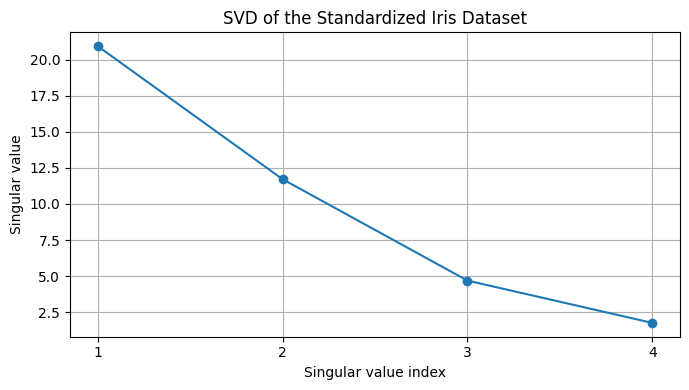

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(
    range(1, len(singular_values) + 1),
    singular_values,
    marker="o"
)
plt.xticks(range(1, len(singular_values) + 1))
plt.xlabel("Singular value index")
plt.ylabel("Singular value")
plt.title("SVD of the Standardized Iris Dataset")
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
print("Rank k approximation errors")

for k in [1, 2, 3]:
    #truncated SVD
    Xk = (
        U[:, :k]
        @ np.diag(singular_values[:k])
        @ Vt[:k, :]
    )

    #spectral norm (matrix 2norm)
    error_2 = np.linalg.norm(X - Xk, ord=2)

    #frobenius norm
    error_F = np.linalg.norm(X - Xk, ord="fro")

    print(f"k = {k}")
    print(f"  Spectral error:  {error_2:.6f}")
    print(f"  Frobenius error: {error_F:.6f}")

Rank k approximation errors
k = 1
  Spectral error:  11.709166
  Frobenius error: 12.736771
k = 2
  Spectral error:  4.691858
  Frobenius error: 5.012061
k = 3
  Spectral error:  1.762732
  Frobenius error: 1.762732
